
# Assignment 3: Q-Learning vs. SARSA in Cliff Walking

## Project Overview

This project compares two reinforcement learning algorithms:

- **Q-Learning:** An off-policy algorithm.
- **SARSA:** An on-policy algorithm.

Both agents learn to navigate a Cliff Walking environment from a start position to a goal while avoiding dangerous cliff cells.

### Objectives

1. Implement Q-Learning and SARSA from scratch.
2. Train both agents under comparable conditions.
3. Evaluate performance across at least five random seeds.
4. Compare episode rewards, steps, and cliff falls.
5. Visualize learning curves and learned policies.
6. Explain how on-policy and off-policy learning affect behavior.

### Tools
- Python
- NumPy
- Matplotlib
- Pandas

### Environment
Google Colab / Jupyter Notebook



### Computational Environment

The following information records the Python version and hardware used to execute the experiments.


In [1]:

import platform
import subprocess

print("Python version:", platform.python_version())
print("CPU:", subprocess.getoutput("lscpu | grep 'Model name'"))
print("GPU:", subprocess.getoutput(
    "nvidia-smi --query-gpu=name --format=csv,noheader"
))


Python version: 3.13.16
CPU: Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
GPU: Tesla T4



### 1. Import Required Libraries


In [2]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("Libraries imported successfully!")

Libraries imported successfully!



NumPy was imported to create Q-tables, perform calculations, and manage random number generation.

Matplotlib was imported to visualize learning curves and learned policies.

Pandas was imported to organize and compare the experimental results of Q-Learning and SARSA.


### 2. Cliff Walking Environment

#### 2.1 Define the Grid and Rewards

In [3]:

# Define the dimensions of the grid
ROWS = 4
COLUMNS = 12

# Define important positions
START = (3, 0)
GOAL = (3, 11)

# Define cliff positions
CLIFF = [(3, col) for col in range(1, 11)]

# Define rewards
STEP_REWARD = -1
CLIFF_REWARD = -100

# Define available actions
ACTIONS = ["up", "down", "left", "right"]

# Display environment settings
print("Grid size:", ROWS, "x", COLUMNS)
print("Start position:", START)
print("Goal position:", GOAL)
print("Cliff positions:", CLIFF)
print("Available actions:", ACTIONS)


Grid size: 4 x 12
Start position: (3, 0)
Goal position: (3, 11)
Cliff positions: [(3, 1), (3, 2), (3, 3), (3, 4), (3, 5), (3, 6), (3, 7), (3, 8), (3, 9), (3, 10)]
Available actions: ['up', 'down', 'left', 'right']



**Explanation:**

- A 4 × 12 grid was defined to represent the Cliff Walking environment.
- The agent starts at position `(3, 0)` and must reach the goal at `(3, 11)`.
- The cliff occupies the bottom row between the start and goal.
- The agent can move up, down, left, or right.
- A reward of `-1` is assigned to each normal step to encourage shorter paths.
- A penalty of `-100` is assigned when the agent falls into the cliff to discourage risky movements.

**Why we did this:**

The environment provides a common setting for comparing Q-Learning and SARSA. Both algorithms will use the same grid, actions, and rewards to ensure a fair comparison.



#### 2.2 Implement Agent Movements


In [4]:

def step(state, action):
    """
    Move the agent one step in the Cliff Walking environment.

    Returns:
        next_state: Agent's new position
        reward: Reward received
        done: Whether the episode has ended
        fell: Whether the agent fell into the cliff
    """

    row, col = state

    # Move according to the selected action
    if action == "up":
        row -= 1
    elif action == "down":
        row += 1
    elif action == "left":
        col -= 1
    elif action == "right":
        col += 1
    else:
        raise ValueError(f"Invalid action: {action}")

    # Keep the agent inside the grid
    row = max(0, min(row, ROWS - 1))
    col = max(0, min(col, COLUMNS - 1))

    next_state = (row, col)

    # Check whether the agent fell into the cliff
    if next_state in CLIFF:
        return START, CLIFF_REWARD, False, True

    # Check whether the agent reached the goal
    if next_state == GOAL:
        return GOAL, STEP_REWARD, True, False

    # Normal movement
    return next_state, STEP_REWARD, False, False


In [5]:

# Test 1: Move up from the start
print("Move up:", step(START, "up"))

# Test 2: Move right from the start (into the cliff)
print("Move right:", step(START, "right"))

# Test 3: Move right from the cell above the goal
print("Reach goal:", step((2, 11), "down"))

# Test 4: Try moving outside the grid
print("Boundary:", step((0, 0), "up"))


Move up: ((2, 0), -1, False, False)
Move right: ((3, 0), -100, False, True)
Reach goal: ((3, 11), -1, True, False)
Boundary: ((0, 0), -1, False, False)



**Explanation:**

- The `step()` function controls the agent's movement in the Cliff Walking environment.
- The agent can move up, down, left, or right.
- Grid boundaries prevent the agent from moving outside the environment.
- If the agent enters a cliff cell, it receives a penalty of `-100` and returns to the start position without ending the episode.
- If the agent reaches the goal, the episode ends.
- Normal movements receive a reward of `-1`.
- The function returns the next state, reward, episode completion status, and cliff-fall status.

**Testing the Environment:**

- **Move Up:** The agent moves from `(3, 0)` to `(2, 0)`.
- **Move Right:** The agent enters the cliff, receives `-100`, and returns to the start.
- **Move Down:** The agent moves from `(2, 11)` to the goal `(3, 11)`, ending the episode.
- **Boundary Test:** The agent attempts to move up from `(0, 0)` but remains inside the grid.

**Why we did this:**

The movement function defines how the environment responds to the agent's actions. Testing different movements ensures that the grid boundaries, cliff penalties, and goal conditions work correctly.

Both Q-Learning and SARSA will use the same environment to ensure a fair comparison.


### 3. Q-Learning Implementation

#### 3.1 Initialize the Q-Table

In [6]:

# Initialize the Q-table with zeros
Q_table = np.zeros((ROWS, COLUMNS, len(ACTIONS)))

# Display Q-table information
print("Q-table shape:", Q_table.shape)
print("Total Q-values:", Q_table.size)
print("Initial Q-values at Start:", Q_table[START])


Q-table shape: (4, 12, 4)
Total Q-values: 192
Initial Q-values at Start: [0. 0. 0. 0.]



**Explanation:**

- A Q-table was initialized using NumPy with dimensions `(4, 12, 4)`.
- The first two dimensions represent the agent's position in the grid.
- The third dimension represents the four possible actions: up, down, left, and right.
- All Q-values were initialized to zero because the agent has not learned the value of any action yet.
- The Q-table contains 192 state-action values.

**Why we did this:**

Q-Learning requires a Q-table to store the estimated value of taking each action in each state. During training, the agent will update these values based on the rewards it receives and its estimates of future rewards.



#### 3.2 Implement Epsilon-Greedy Action Selection


In [7]:

def choose_action(q_table, state, epsilon, rng):
    """
    Select an action using the epsilon-greedy strategy.

    Args:
        q_table: Table containing Q-values
        state: Current agent position
        epsilon: Exploration probability
        rng: Random number generator

    Returns:
        Selected action as a string
    """

    # Exploration: choose a random action
    if rng.random() < epsilon:
        return rng.choice(ACTIONS)

    # Exploitation: choose an action with the highest Q-value
    q_values = q_table[state]
    best_actions = np.flatnonzero(q_values == np.max(q_values))

    # Randomly break ties between equally good actions
    action_index = rng.choice(best_actions)

    return ACTIONS[action_index]


In [8]:

# Create a reproducible random number generator
rng = np.random.default_rng(42)

# Test exploration
print("Exploration:", choose_action(Q_table, START, 1.0, rng))

# Give the Up action the highest Q-value
Q_table[START] = [10, 2, 3, 5]

# Test exploitation
print("Exploitation:", choose_action(Q_table, START, 0.0, rng))


Exploration: left
Exploitation: up



**Explanation:**

- The `choose_action()` function selects an action using the epsilon-greedy strategy.
- With probability `epsilon`, the agent explores by selecting a random action.
- Otherwise, it exploits by choosing an action with the highest estimated Q-value.
- When multiple actions have the same maximum Q-value, one is selected randomly.
- A NumPy random number generator is used to make the experiments reproducible.

**Why we did this:**

Epsilon-greedy balances exploration and exploitation during reinforcement learning. Exploration allows the agent to discover new actions, while exploitation uses previously learned Q-values.

The same action-selection function will be used by Q-Learning and SARSA to ensure a fair comparison.



#### 3.3 Train the Q-Learning Agent


In [9]:

def train_q_learning(episodes=500, alpha=0.5, gamma=0.9,
                     epsilon=0.1, seed=42, max_steps=1000):
    """
    Train a Q-Learning agent in the Cliff Walking environment.
    """

    rng = np.random.default_rng(seed)
    q_table = np.zeros((ROWS, COLUMNS, len(ACTIONS)))

    episode_rewards = []
    episode_steps = []
    episode_falls = []

    for episode in range(episodes):
        state = START
        total_reward = 0
        steps = 0
        falls = 0

        for _ in range(max_steps):

            # Select an action using epsilon-greedy
            action = choose_action(q_table, state, epsilon, rng)

            # Take the action in the environment
            next_state, reward, done, fell = step(state, action)

            # Find the best estimated next Q-value
            best_next_q = 0 if done else np.max(q_table[next_state])

            # Update Q-value using Q-Learning
            action_index = ACTIONS.index(action)

            old_q = q_table[state][action_index]

            q_table[state][action_index] = old_q + alpha * (
                reward + gamma * best_next_q - old_q
            )

            # Record the results
            total_reward += reward
            steps += 1
            falls += int(fell)

            state = next_state

            if done:
                break

        episode_rewards.append(total_reward)
        episode_steps.append(steps)
        episode_falls.append(falls)

    return q_table, episode_rewards, episode_steps, episode_falls



In [10]:
q_table, rewards, steps, falls = train_q_learning()

print("Training completed!")
print("Episodes:", len(rewards))
print("Average reward (last 100):", np.mean(rewards[-100:]))
print("Average steps (last 100):", np.mean(steps[-100:]))
print("Total cliff falls:", sum(falls))

Training completed!
Episodes: 500
Average reward (last 100): -46.66
Average steps (last 100): 16.96
Total cliff falls: 163



**Explanation:**

- A fresh Q-table was initialized with zeros.
- The agent starts each episode at the starting position.
- Actions are selected using the epsilon-greedy strategy.
- Q-values are updated using the Q-Learning formula, which selects the highest estimated Q-value of the next state.
- The agent receives rewards and penalties based on its actions.
- Episode rewards, steps, and cliff falls are recorded for performance evaluation.

**Training Results (500 Episodes, Seed 42):**

- Average reward over the last 100 episodes: `-46.66`
- Average steps over the last 100 episodes: `16.96`
- Total cliff falls across 500 episodes: `163`

**Why we did this:**

Q-Learning trains the agent to select actions that maximize expected future rewards. Recording these results allows us to evaluate its learning performance and compare it with SARSA.

These results represent a single training run. The final experiment will use at least five random seeds and report mean and standard deviation to ensure a reliable comparison.



### 4. SARSA Implementation




#### 4.1 Train the SARSA Agent

In [11]:

def train_sarsa(episodes=500, alpha=0.5, gamma=0.9,
                epsilon=0.1, seed=42, max_steps=1000):
    """
    Train a SARSA agent in the Cliff Walking environment.
    """

    rng = np.random.default_rng(seed)
    q_table = np.zeros((ROWS, COLUMNS, len(ACTIONS)))

    episode_rewards = []
    episode_steps = []
    episode_falls = []

    for episode in range(episodes):
        state = START
        action = choose_action(q_table, state, epsilon, rng)

        total_reward = 0
        steps = 0
        falls = 0

        for _ in range(max_steps):

            # Take the selected action
            next_state, reward, done, fell = step(state, action)

            # Select the next action using the current policy
            if done:
                next_q = 0
                next_action = None
            else:
                next_action = choose_action(
                    q_table, next_state, epsilon, rng
                )
                next_q = q_table[next_state][ACTIONS.index(next_action)]

            # Update Q-value using SARSA
            action_index = ACTIONS.index(action)
            old_q = q_table[state][action_index]

            q_table[state][action_index] = old_q + alpha * (
                reward + gamma * next_q - old_q
            )

            # Record training results
            total_reward += reward
            steps += 1
            falls += int(fell)

            # Move to the next state and action
            state = next_state
            action = next_action

            if done:
                break

        episode_rewards.append(total_reward)
        episode_steps.append(steps)
        episode_falls.append(falls)

    return q_table, episode_rewards, episode_steps, episode_falls


In [12]:

sarsa_q_table, sarsa_rewards, sarsa_steps, sarsa_falls = train_sarsa()

print("SARSA training completed!")
print("Episodes:", len(sarsa_rewards))
print("Average reward (last 100):", np.mean(sarsa_rewards[-100:]))
print("Average steps (last 100):", np.mean(sarsa_steps[-100:]))
print("Total cliff falls:", sum(sarsa_falls))


SARSA training completed!
Episodes: 500
Average reward (last 100): -26.33
Average steps (last 100): 21.38
Total cliff falls: 60



**Explanation:**

- A fresh Q-table was initialized with zeros for SARSA.
- The agent selects actions using the epsilon-greedy strategy.
- After each movement, the environment returns the next state and reward.
- SARSA updates its Q-values using the next action selected by its current policy rather than the maximum possible Q-value.
- Episode rewards, steps, and cliff falls are recorded.

**Training Results (500 Episodes, Seed 42):**

- Average reward over the last 100 episodes: `-26.33`
- Average steps over the last 100 episodes: `21.38`
- Total cliff falls across 500 episodes: `60`

**Why we did this:**

SARSA is an on-policy algorithm that learns from actions selected by its current policy, including exploratory actions.

In this initial experiment, SARSA achieved better average rewards and fewer cliff falls than Q-Learning, although it required more steps.

These results are based on a single random seed. Further experiments using at least five random seeds are required for a reliable comparison.



### 5. Experimental Comparison




#### 5.1 Train Both Algorithms Using Multiple Random Seeds

In [13]:

# Define experimental settings
SEEDS = [42, 123, 456, 2026, 1313291]
EPISODES = 500
ALPHA = 0.5
GAMMA = 0.9
EPSILON = 0.1

# Store results from all runs
results = {
    "Q-Learning": {
        "rewards": [],
        "steps": [],
        "falls": [],
        "q_tables": []
    },
    "SARSA": {
        "rewards": [],
        "steps": [],
        "falls": [],
        "q_tables": []
    }
}

# Train both algorithms using the same seeds
for seed in SEEDS:

    # Train Q-Learning
    q_table, rewards, steps, falls = train_q_learning(
        episodes=EPISODES,
        alpha=ALPHA,
        gamma=GAMMA,
        epsilon=EPSILON,
        seed=seed
    )

    results["Q-Learning"]["q_tables"].append(q_table)
    results["Q-Learning"]["rewards"].append(rewards)
    results["Q-Learning"]["steps"].append(steps)
    results["Q-Learning"]["falls"].append(falls)

    # Train SARSA
    q_table, rewards, steps, falls = train_sarsa(
        episodes=EPISODES,
        alpha=ALPHA,
        gamma=GAMMA,
        epsilon=EPSILON,
        seed=seed
    )

    results["SARSA"]["q_tables"].append(q_table)
    results["SARSA"]["rewards"].append(rewards)
    results["SARSA"]["steps"].append(steps)
    results["SARSA"]["falls"].append(falls)

    print(f"Seed {seed}: Both algorithms completed")

print("\nAll experiments completed!")


Seed 42: Both algorithms completed
Seed 123: Both algorithms completed
Seed 456: Both algorithms completed
Seed 2026: Both algorithms completed
Seed 1313291: Both algorithms completed

All experiments completed!



#### 5.2 Visualize Learning Curves


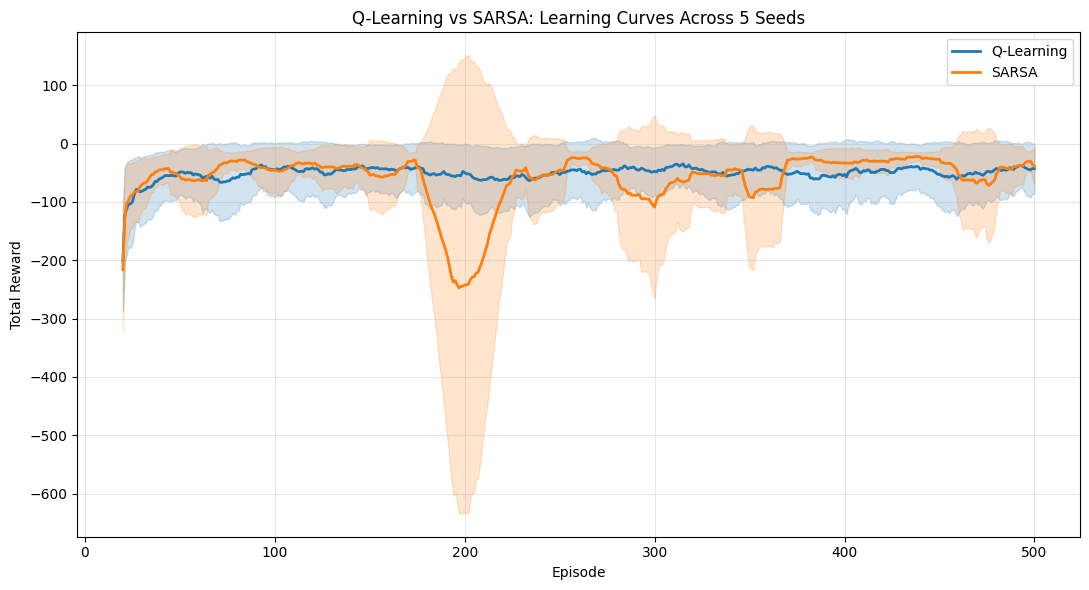

In [14]:

plt.figure(figsize=(11, 6))

for algorithm in ["Q-Learning", "SARSA"]:

    # Convert rewards from five runs into a NumPy array
    rewards_array = np.array(results[algorithm]["rewards"])

    # Calculate mean and standard deviation across seeds
    mean_rewards = np.mean(rewards_array, axis=0)
    std_rewards = np.std(rewards_array, axis=0)

    # Smooth the mean for easier visualization
    window = 20
    smoothed_mean = np.convolve(
        mean_rewards, np.ones(window) / window, mode="valid"
    )

    episodes_axis = np.arange(window, EPISODES + 1)

    # Plot the learning curve
    line, = plt.plot(
        episodes_axis,
        smoothed_mean,
        label=algorithm,
        linewidth=2
    )

    # Smooth standard deviation for visualization
    smoothed_std = np.convolve(
        std_rewards, np.ones(window) / window, mode="valid"
    )

    plt.fill_between(
        episodes_axis,
        smoothed_mean - smoothed_std,
        smoothed_mean + smoothed_std,
        color=line.get_color(),
        alpha=0.2
    )

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Q-Learning vs SARSA: Learning Curves Across 5 Seeds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the learning curve for GitHub and the report
plt.savefig("learning_curves.png", dpi=300, bbox_inches="tight")

plt.show()



**Explanation:**

- Episode rewards from five random seeds were collected for both algorithms.
- The mean reward and standard deviation were calculated across the five runs for each episode.
- A moving average with a window of 20 episodes was applied to make the learning curves easier to interpret.
- Both algorithms were plotted on the same graph.
- Shaded regions were added to illustrate variability across runs.

- The learning curve was saved as `learning_curves.png` at 300 DPI for use in the final report and GitHub repository.


**Why we did this:**

Learning curves help compare how Q-Learning and SARSA improve during training.

Using multiple random seeds and showing variability makes the comparison more reliable than using a single training run.



### 6. Visualize Learned Policies




#### 6.1 Display Q-Learning and SARSA Policies

In [15]:

# Symbols representing the four possible actions
ARROWS = {
    "up": "↑",
    "down": "↓",
    "left": "←",
    "right": "→"
}

def display_policy(q_table, algorithm):
    """
    Display the greedy policy learned by an agent.
    """

    print(f"\n{algorithm} Learned Policy")
    print("-" * 35)

    for row in range(ROWS):
        symbols = []

        for col in range(COLUMNS):
            state = (row, col)

            if state == START:
                symbol = "S"
            elif state == GOAL:
                symbol = "G"
            elif state in CLIFF:
                symbol = "C"
            else:
                # Select the action with the highest Q-value
                best_action_index = np.argmax(q_table[state])
                best_action = ACTIONS[best_action_index]
                symbol = ARROWS[best_action]

            symbols.append(symbol)

        print(" ".join(symbols))


# Display policies from the same random seed
seed_index = 4

display_policy(
    results["Q-Learning"]["q_tables"][seed_index],
    f"Q-Learning (Seed {SEEDS[seed_index]})"
)

display_policy(
    results["SARSA"]["q_tables"][seed_index],
    f"SARSA (Seed {SEEDS[seed_index]})"
)



Q-Learning (Seed 1313291) Learned Policy
-----------------------------------
← → ← → → ↓ → ↑ → → ↓ ↓
↓ ↓ → → ↓ → ↓ → ↓ → → ↓
→ → → → → → → → → → → ↓
S C C C C C C C C C C G

SARSA (Seed 1313291) Learned Policy
-----------------------------------
→ → → → → → → → → → → ↓
↑ ← ↑ ↑ → ↑ ↑ ← ↑ → ↑ ↓
↑ ↑ ↑ ↑ → ↑ ↑ ↑ ↑ → → ↓
S C C C C C C C C C C G



**Explanation:**

- The learned policies of Q-Learning and SARSA were displayed using directional arrows.
- Each arrow represents the action with the highest Q-value at that grid position.
- The start (`S`), goal (`G`), and cliff (`C`) positions were labeled separately.
- Both policies were displayed using the same random seed (`1313291`) for a consistent comparison.
- Q-Learning and SARSA produced different action preferences in several states.

**Why we did this:**

Visualizing the learned policies helps us compare how Q-Learning and SARSA navigate the Cliff Walking environment.

Q-Learning often learns a shorter path close to the cliff, while SARSA may learn a longer but safer path because it accounts for exploratory actions.

The displayed arrows represent the greedy policies learned after training. A complete route from the start to the goal must be traced separately to confirm which policy travels closer to the cliff.

**Note:** The policies shown are from seed `1313291`. Learned policies may vary across random seeds.



#### 6.2 Visualize the Paths Learned by Q-Learning and SARSA


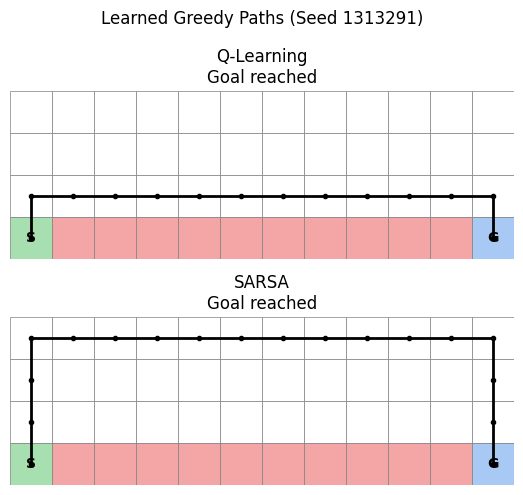

Q-Learning: Goal reached | Steps: 13
SARSA: Goal reached | Steps: 17


In [16]:

def trace_path(q_table, max_steps=200):
    """
    Follow the greedy policy from Start to Goal.
    Detect repeated states to avoid infinite loops.
    """
    state = START
    path = [state]
    visited = {state}

    for _ in range(max_steps):
        best_index = np.argmax(q_table[state])
        action = ACTIONS[best_index]

        next_state, reward, done, fell = step(state, action)
        path.append(next_state)

        if fell:
            return path, "Cliff fall"

        if done:
            return path, "Goal reached"

        if next_state in visited:
            return path, "Loop detected"

        visited.add(next_state)
        state = next_state

    return path, "Step limit reached"


def plot_path(ax, path, title, status):
    """Display a learned route on the Cliff Walking grid."""

    # Draw grid cells
    for row in range(ROWS):
        for col in range(COLUMNS):
            color = "white"

            if (row, col) in CLIFF:
                color = "#f4a6a6"
            elif (row, col) == START:
                color = "#a8dfb0"
            elif (row, col) == GOAL:
                color = "#a9c9f5"

            ax.add_patch(
                plt.Rectangle(
                    (col, row), 1, 1,
                    facecolor=color,
                    edgecolor="gray",
                    linewidth=0.5
                )
            )

    # Draw route
    x = [col + 0.5 for row, col in path]
    y = [row + 0.5 for row, col in path]

    ax.plot(x, y, color="black", linewidth=2, marker="o",
            markersize=3)

    # Label start and goal
    ax.text(0.5, 3.5, "S", ha="center", va="center",
            fontweight="bold")
    ax.text(11.5, 3.5, "G", ha="center", va="center",
            fontweight="bold")

    ax.set_xlim(0, COLUMNS)
    ax.set_ylim(ROWS, 0)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{title}\n{status}")


# Select the same seed for both algorithms
seed_index = 4
selected_seed = SEEDS[seed_index]

q_path, q_status = trace_path(
    results["Q-Learning"]["q_tables"][seed_index]
)

sarsa_path, sarsa_status = trace_path(
    results["SARSA"]["q_tables"][seed_index]
)

# Display both routes
fig, axes = plt.subplots(2, 1, figsize=(12, 5))

plot_path(axes[0], q_path, "Q-Learning", q_status)
plot_path(axes[1], sarsa_path, "SARSA", sarsa_status)

fig.suptitle(f"Learned Greedy Paths (Seed {selected_seed})")
plt.tight_layout()

# Save figure for GitHub and the report
plt.savefig("learned_paths.png", dpi=300, bbox_inches="tight")
plt.show()

print("Q-Learning:", q_status, "| Steps:", len(q_path) - 1)
print("SARSA:", sarsa_status, "| Steps:", len(sarsa_path) - 1)



**Explanation:**

- The learned greedy paths of Q-Learning and SARSA were visualized using seed `1313291`.
- Both algorithms successfully reached the goal.
- Q-Learning reached the goal in `13 steps` by following a shorter route close to the cliff.
- SARSA reached the goal in `17 steps` by following a longer route farther from the cliff.
- The paths were evaluated using greedy action selection without exploration.
- The visualization was saved as `learned_paths.png`.

**Why we did this:**

Visualizing the paths helps explain the behavioral difference between Q-Learning and SARSA.

Q-Learning learns using the best estimated next action, which can favor shorter paths near the cliff.

SARSA learns using actions selected by its current epsilon-greedy policy. Because exploration can cause cliff falls, SARSA may learn a longer but safer route.

These observations are based on seed `1313291`. Results across multiple random seeds will be considered in the final comparison.



### 7. Performance Comparison




#### 7.1 Calculate Mean and Standard Deviation Across Random Seeds

In [17]:

# Evaluate performance over the last 100 episodes
LAST_N = 100

performance_data = []

for algorithm in ["Q-Learning", "SARSA"]:

    seed_rewards = []
    seed_steps = []
    seed_falls = []

    for i, seed in enumerate(SEEDS):

        # Calculate average performance for each seed
        avg_reward = np.mean(
            results[algorithm]["rewards"][i][-LAST_N:]
        )

        avg_steps = np.mean(
            results[algorithm]["steps"][i][-LAST_N:]
        )

        avg_falls = np.mean(
            results[algorithm]["falls"][i][-LAST_N:]
        )

        seed_rewards.append(avg_reward)
        seed_steps.append(avg_steps)
        seed_falls.append(avg_falls)

    # Calculate mean and standard deviation across seeds
    performance_data.append({
        "Algorithm": algorithm,
        "Average Reward": (
            f"{np.mean(seed_rewards):.2f} ± "
            f"{np.std(seed_rewards):.2f}"
        ),
        "Average Steps": (
            f"{np.mean(seed_steps):.2f} ± "
            f"{np.std(seed_steps):.2f}"
        ),
        "Cliff Falls": (
            f"{np.mean(seed_falls):.2f} ± "
            f"{np.std(seed_falls):.2f}"
        )
    })

# Create a comparison table
performance_df = pd.DataFrame(performance_data)

display(performance_df)


,Algorithm,Average Reward,Average Steps,Cliff Falls
0,Q-Learning,-46.51 ± 3.66,16.81 ± 0.67,0.30 ± 0.03
1,SARSA,-39.73 ± 29.17,34.58 ± 26.19,0.05 ± 0.04


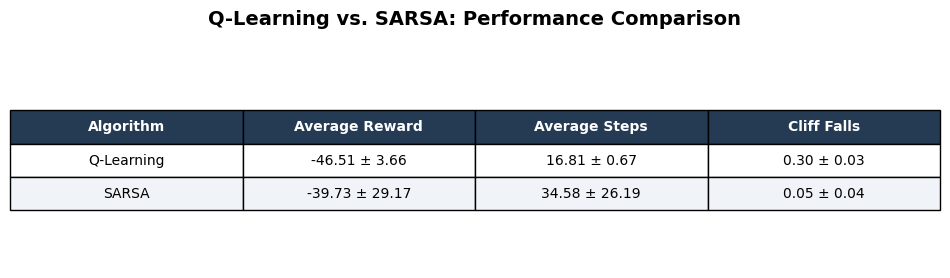

Performance comparison saved as PNG!


In [18]:

# Create a professional comparison table
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.axis("off")

table = ax.table(
    cellText=performance_df.values,
    colLabels=performance_df.columns,
    cellLoc="center",
    loc="center"
)

# Format the table
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

# Style the header
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor("#243B53")
        cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor(
            "#F0F4F8" if row % 2 == 0 else "white"
        )

ax.set_title(
    "Q-Learning vs. SARSA: Performance Comparison",
    fontsize=14,
    fontweight="bold",
    pad=20
)

# Save the table as a high-resolution image
plt.savefig(
    "performance_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Performance comparison saved as PNG!")



**Explanation:**

- Performance was evaluated using the final 100 episodes of each training run.
- Mean and standard deviation were calculated across five random seeds for average reward, average steps, and cliff falls.
- The results were organized into a comparison table.
- The table was exported as `performance_comparison.png` at 300 DPI.

**Why we did this:**

The comparison table summarizes the performance of Q-Learning and SARSA across multiple training runs.

Saving the results as a high-resolution PNG allows the table to be included in the assignment report and GitHub documentation.



#### 7.2 Interpretation of Experimental Results

**Results:**

- **Average Reward:** SARSA achieved a higher average reward (-39.73) than Q-Learning (-46.51), but showed greater variability across random seeds.
- **Average Steps:** Q-Learning required fewer steps (16.81) compared with SARSA (34.58).
- **Cliff Falls:** SARSA experienced fewer cliff falls per episode (0.05) than Q-Learning (0.30).

**Analysis:**

Q-Learning learned shorter routes but experienced more cliff falls during exploration.

SARSA generally learned safer behavior by considering the actions selected under its epsilon-greedy policy. However, its performance varied substantially across the five random seeds.

**Conclusion:**

The results illustrate the trade-off between shorter routes and safety. Q-Learning was more efficient in terms of steps, while SARSA experienced fewer cliff falls.

These conclusions are based on the selected training settings and five random seeds.



### 7.3 Per-Seed Performance Analysis

**What:** Compare Q-Learning and SARSA separately for each of the five random seeds using the final 100 training episodes.

**Why:** Overall mean ± standard deviation can hide differences between individual runs. A per-seed comparison helps identify which algorithm performs better for each seed and whether the results are consistent.

The detailed interpretation is provided in Section 4.4 of the accompanying report.


In [19]:

# Section 7.3 — Per-Seed Performance Analysis
# Calculate metrics over the final 100 episodes of each run.

rows = []

for i, seed in enumerate(SEEDS):
    row = {"Seed": seed}

    for algorithm in ["Q-Learning", "SARSA"]:
        run = results[algorithm]

        row[f"{algorithm} Reward"] = np.mean(
            run["rewards"][i][-100:]
        )
        row[f"{algorithm} Steps"] = np.mean(
            run["steps"][i][-100:]
        )
        row[f"{algorithm} Falls"] = np.mean(
            run["falls"][i][-100:]
        )

    q_reward = row["Q-Learning Reward"]
    s_reward = row["SARSA Reward"]

    row["Higher Reward"] = (
        "Q-Learning" if q_reward > s_reward
        else "SARSA" if s_reward > q_reward
        else "Tie"
    )

    rows.append(row)

per_seed_df = pd.DataFrame(rows)

# Display results rounded to two decimal places
display(per_seed_df.round(2))


,Seed,Q-Learning Reward,Q-Learning Steps,Q-Learning Falls,SARSA Reward,SARSA Steps,SARSA Falls,Higher Reward
0,42,-46.66,16.96,0.30,-26.33,21.38,0.05,SARSA
1,123,-45.40,16.69,0.29,-20.96,19.97,0.01,SARSA
2,456,-51.22,17.56,0.34,-29.05,22.12,0.07,SARSA
3,2026,-40.35,15.60,0.25,-97.82,86.93,0.11,Q-Learning
4,1313291,-48.91,17.23,0.32,-24.47,22.49,0.02,SARSA
